In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#***1***
<p>Generate 600 fictional auto-rickshaw trips in a notebook named 'auto_trips.ipynb' with seed 42: trip_id, trip_date (30 days from 01/04/2025), area (Navrangpura, Maninagar, Satellite, Vastrapur, Paldi), distance_km 1 to 15, fare_inr = 30 + 14 x distance + noise from -15 to 25, rounded. Save 'auto_trips.csv', then draw a line plot of daily total fare using `resample('D')`, with a title and axis labels, as 'daily_fare_line.png'. Hint: `resample` needs trip_date set as the index.</p>

In [2]:
df=pd.read_csv('auto_trips.csv')

In [3]:
df.head()

,trip_id,trip_date,area,distance_km,fare_inr
0,1,2025-04-07,Navrangpura,13.765934,217.0
1,2,2025-04-20,Paldi,2.947627,58.0
2,3,2025-04-29,Paldi,2.411124,62.0
3,4,2025-04-15,Paldi,4.584217,94.0
4,5,2025-04-11,Satellite,11.165338,180.0


In [4]:
df['trip_date']=pd.to_datetime(df['trip_date'])
df=df.set_index('trip_date')

In [5]:
a=df['fare_inr'].resample('D').sum()

In [6]:
a   #total fare of all 30 days

,fare_inr
trip_date,
2025-04-01,4572.0
2025-04-02,2879.0
2025-04-03,4596.0
2025-04-04,2722.0
2025-04-05,2585.0
2025-04-06,2329.0
2025-04-07,3030.0
2025-04-08,3569.0
2025-04-09,2236.0


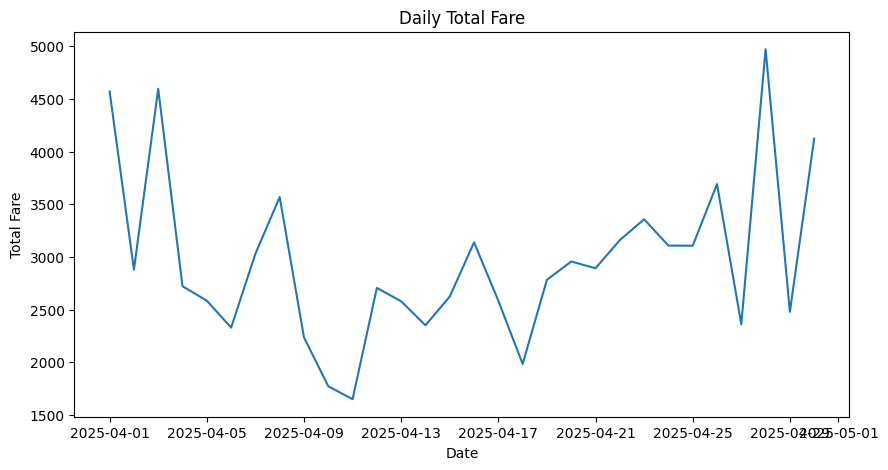

In [7]:
plt.figure(figsize=(10,5))
plt.plot(a)
plt.title('Daily Total Fare')
plt.xlabel('Date')
plt.ylabel('Total Fare')
plt.savefig('daily_fare.png')
plt.show()

#***2***
<p>Plot `distance_km` against `fare_inr` as a scatter chart with two series, trips up to 5 km in orange and longer trips in teal, with `alpha=0.6`, a legend, a title, axis labels and `figsize=(8, 5)`. Save it as 'fare_vs_distance.png'. Hint: Call `plt.savefig()` before `plt.show()`, or the file can be blank.</p>


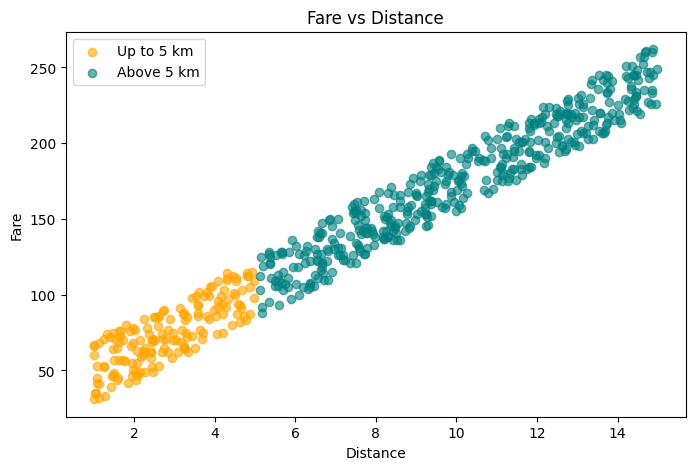

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(df[df['distance_km'] <= 5]['distance_km'],
           df[df['distance_km'] <= 5]['fare_inr'],
           color='orange', alpha=0.6, label='Up to 5 km')

ax.scatter(df[df['distance_km'] > 5]['distance_km'],
           df[df['distance_km'] > 5]['fare_inr'],
           color='teal', alpha=0.6, label='Above 5 km')

ax.set_title('Fare vs Distance')
ax.set_xlabel('Distance')
ax.set_ylabel('Fare')

ax.legend()

plt.savefig('fare & distance.png')
plt.show()

#***3***
<p>Draw a bar chart of trips per area from `value_counts()`, sorted from highest to lowest, with a different colour for each bar. Create the figure with `fig, ax = plt.subplots(figsize=(8, 5))`, draw with `ax.bar`, add a title and axis labels, and save it as 'trips_per_area.png'.</p>


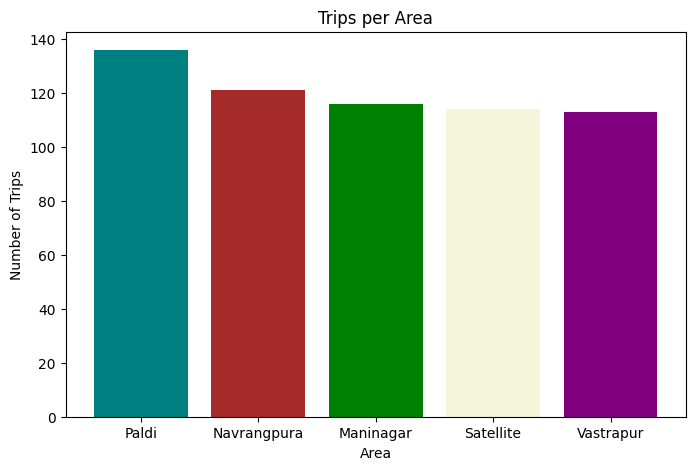

In [9]:
area_count = df['area'].value_counts()

area_count = area_count.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(area_count.index, area_count.values,
       color=['teal', 'brown', 'green', 'beige', 'purple'])

ax.set_title('Trips per Area')
ax.set_xlabel('Area')
ax.set_ylabel('Number of Trips')

plt.savefig('trips_per_area.png')
plt.show()

#***4***
<p>Draw a histogram of `fare_inr` with `ax.hist(bins=15)`, a dashed vertical line for the mean fare using `ax.axvline`, and a legend that shows the mean value. Save it as 'fare_hist.png'. Check with `Path.exists()` that all four PNG files are present. Run Restart & Run All and push to 's10_auto_trips' in your GitHub repo 'ds_analysis_portfolio'.</p>


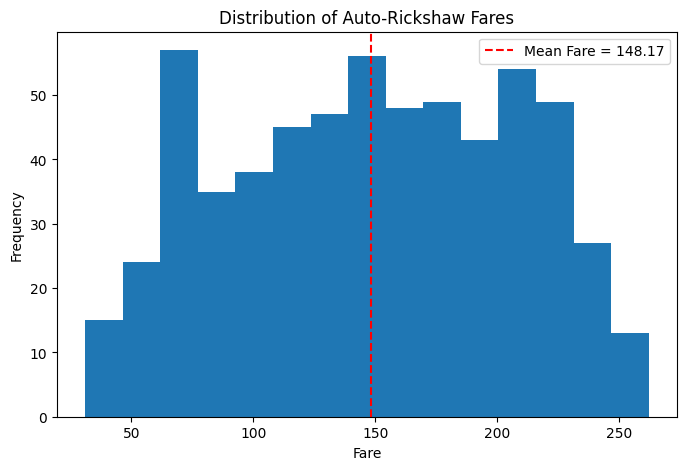

In [10]:
mean_fare = df['fare_inr'].mean()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(df['fare_inr'], bins=15)

ax.axvline(mean_fare, color='red', linestyle='--',
           label=f'Mean Fare = {mean_fare:.2f}')

ax.set_title('Distribution of Auto-Rickshaw Fares')
ax.set_xlabel('Fare')
ax.set_ylabel('Frequency')

ax.legend()

plt.savefig('fare_hist.png')
plt.show()

In [11]:
from pathlib import Path

In [12]:
files = ['daily_fare.png',
         'fare & distance.png',
         'trips_per_area.png',
         'fare_hist.png']

for file in files:
    print(file, Path(file).exists())

daily_fare.png True
fare & distance.png True
trips_per_area.png True
fare_hist.png True
